# 8-2. AnomalyAny 결함 생성 실습 + 내 디버깅 기록

- 첫 코드 셀: 강사 설치 셀에 없던 의존성(`clip`, `pyrallis`)을 추가한 설치 셀
- 강사 셀의 이미지 출력(탁자, 헤이즐넛, PCB)은 **강사가 서버 GPU에서 남긴 출력**이다. T4에서는 강사 원본 셀도 OOM이 난다.
- 맨 아래 C1 셀 3개: T4에서 돌려 보려던 시도 (768 fp32 OOM → fp16 dtype 에러 → autocast OOM). 512 재시도의 OOM 출력은 다시 실행하면서 덮어써졌다.
- 분석은 [`analysis.md`](analysis.md)의 "AnomalyAny 결과 분석"과 "실험 C1"
- 맨 끝에 회고(KPT)가 있다.

**AnomalyAny 강사 출력 4장** (윗줄 결과, 아랫줄 crack attention). attention이 모인 자리는 바뀌지만 균열 모양은 첫 장의 커넥터뿐이다.

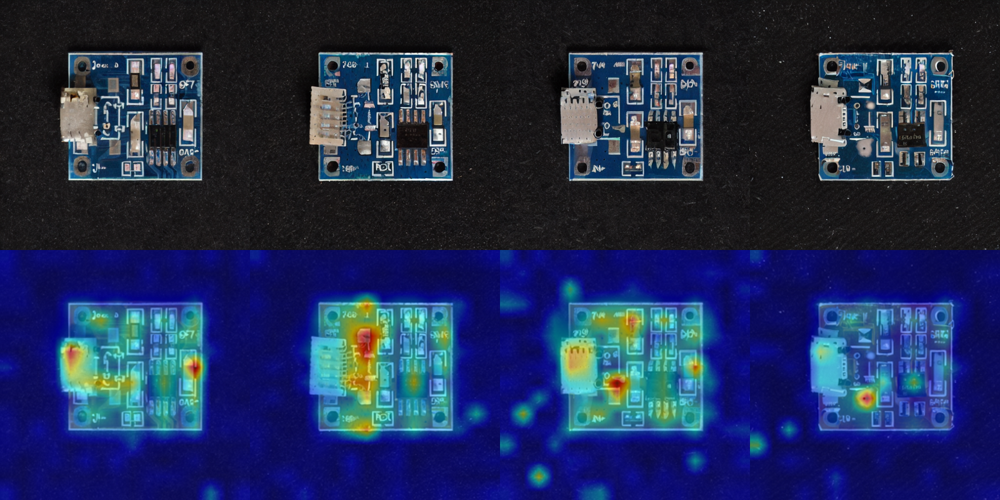

**T4에서 OOM** 같은 SD 1.5인데 일반 생성(8-1)은 3\~6GiB, AnomalyAny는 어떤 설정으로도 T4 한계를 넘었다.

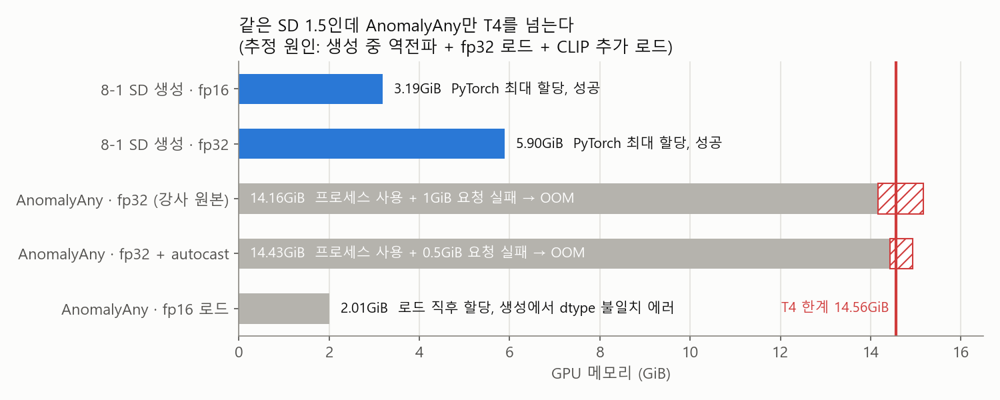


In [1]:
# [준비] 강사 환경과 같은 버전 + AnomalyAny 의존성 (CLIP, pyrallis 등 강사 셀에 없던 것)
!pip install -q diffusers==0.33.1 transformers==4.52.4 accelerate ftfy regex pyrallis
!pip install -q git+https://github.com/openai/CLIP.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 104.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 117.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Preparing metadata (setup.py) ... done


In [2]:
!git clone https://github.com/EPFL-IMOS/AnomalyAny

Cloning into 'AnomalyAny'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects: 100% (87/87), 17.84 MiB | 16.65 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [3]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny


**Reference:** 이 코드는 EPFL-IMOS의 [AnomalyAny GitHub 리포지토리](https://github.com/EPFL-IMOS/AnomalyAny)에서 가져왔습니다.

In [4]:
from typing import List, Dict
import torch

import sys
sys.path.append(".")
sys.path.append("..")

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

%load_ext autoreload
%autoreload 2

ModuleNotFoundError: No module named 'imp'

**내 메모 (위 import 셀)** `%load_ext autoreload` 는 Python 3.12에서 `imp` 모듈이 없어 에러가 난다. 개발 편의 기능이라 무시했고, 위의 AnomalyAny import는 성공한다.

In [5]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

**내 메모 (위 모델 로드 셀)** `from_pretrained` 에 `torch_dtype` 이 없어 **fp32**로 올라간다. AnomalyAny는 crack attention을 키우려고 생성 중에 역전파를 해서, 학습할 때처럼 중간값을 GPU에 들고 있어야 한다. 여기에 호출마다 `clip.load("ViT-L/14")` 가 더해져 T4(14.56GiB)를 넘는 것으로 보인다.
- OOM이 났을 때 내 첫 판단은 슬라이드 p.20의 방법 중 fp16 변환이었다. 해상도를 먼저 의심했다가 코드를 보니 생성 크기가 512로 고정이라 해상도는 원인이 아니었고, 결과적으로 첫 판단이 맞는 방향이었다. 다만 아래처럼 AnomalyAny 내부가 fp32 전제라 fp16만으로는 안 됐다.

In [ ]:
# [fp16 로드] T4 메모리 부족 → p.20 Precision 변환 (Attend-and-Excite 공식 예제도 fp16)
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0')
stable = RelationalAttendAndExcitePipeline.from_pretrained('runwayml/stable-diffusion-v1-5', safety_checker=None, torch_dtype=torch.float16).to(device)
tokenizer = stable.tokenizer
print('unet dtype:', stable.unet.dtype, '| GPU memory after load (GB):', round(torch.cuda.memory_allocated() / 1e9, 2))

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

unet dtype: torch.float16 | GPU memory after load (GB): 2.16


**내 메모 (fp16 로드 시도)** 로드 후 2.16GB로 줄었지만, 생성에서 `mat1 and mat2 must have the same dtype, but got Float and Half`. AnomalyAny 내부가 fp32 입력을 만든다. 정밀도는 코드 전체를 같이 맞춰야 한다 (노드 5).

In [6]:
from PIL import Image

type = "table"
tokens = "8"
prompt = f"a photo of a {type} that is faded"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = f"./example_web/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

**내 메모 (위 프롬프트 셀)** `tokens = "8"` 은 감시할 단어의 번호다. 0번은 문장 시작 표시라서 "a photo of a table that is faded"의 8번은 `faded`, "a photo of a pcb with a crack on it"의 8번은 `crack`. 강사가 결함 단어를 8번 자리에 맞춰 프롬프트를 짰다.

In [7]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=normal_prompt,
                    detailed_prompt=detailed_prompt):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

# Anomaly Generation

In [8]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']


  0%|          | 0/200 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 413.81 MiB is free. Including non-PyTorch memory, this process has 14.16 GiB memory in use. Of the allocated memory 13.81 GiB is allocated by PyTorch, and 220.55 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

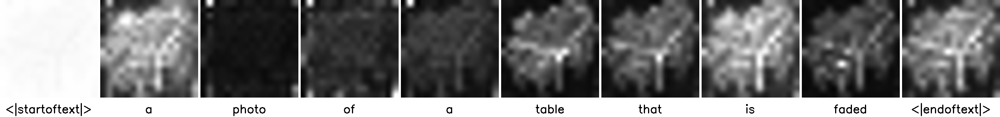

In [ ]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))

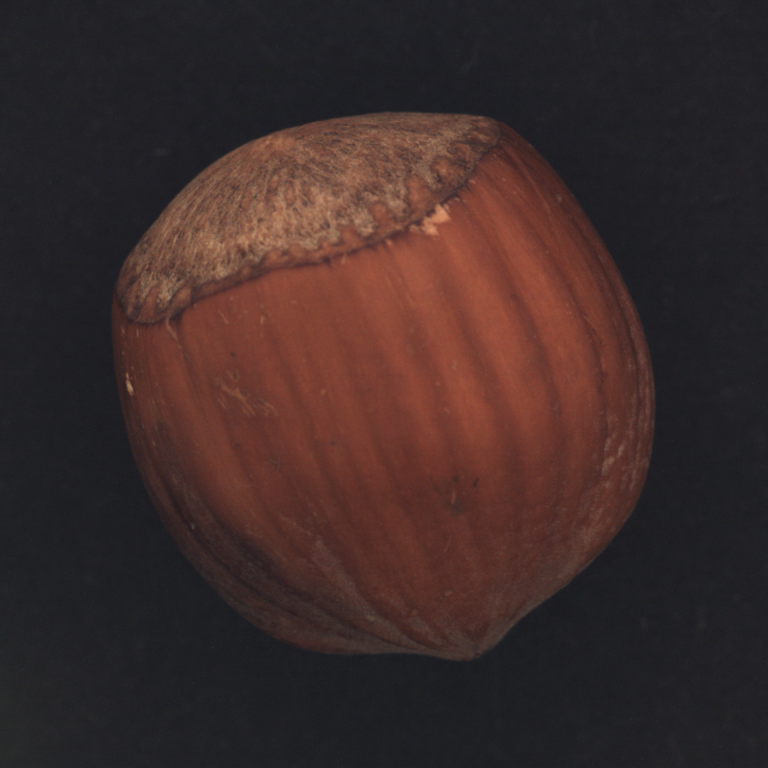

In [ ]:
from PIL import Image

type = "hazelnut"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = f"./example_image/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

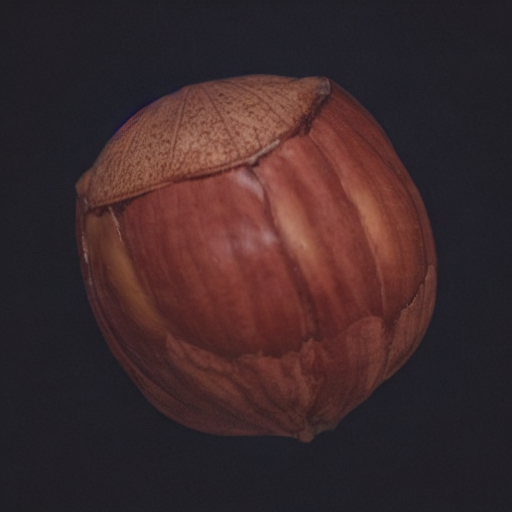

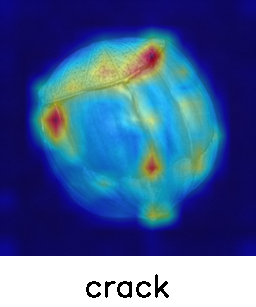

  0%|          | 0/200 [00:00<?, ?it/s]

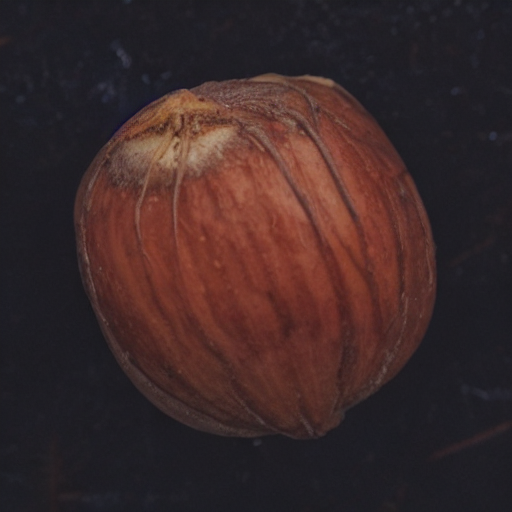

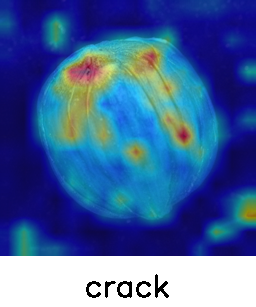

  0%|          | 0/200 [00:00<?, ?it/s]

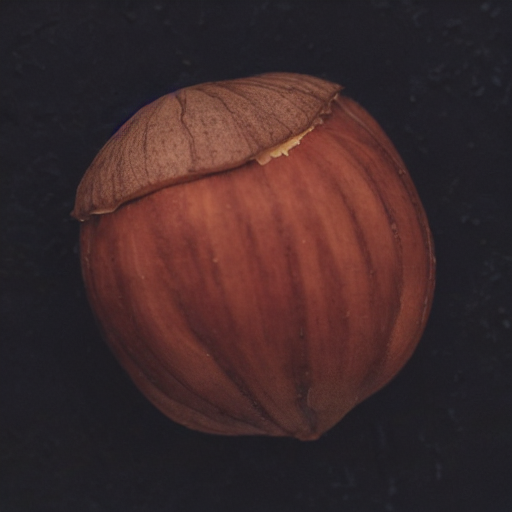

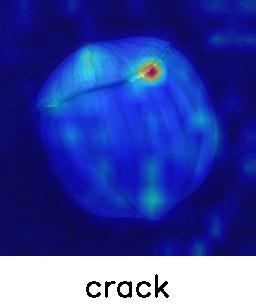

  0%|          | 0/200 [00:00<?, ?it/s]

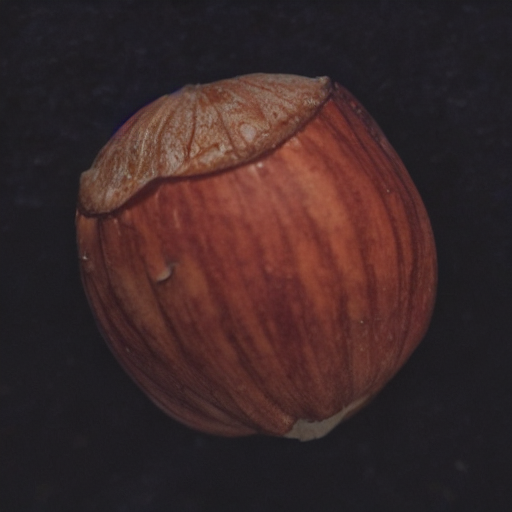

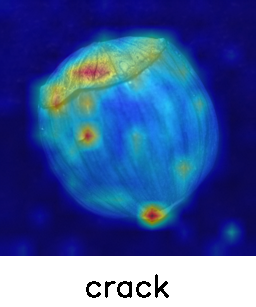

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

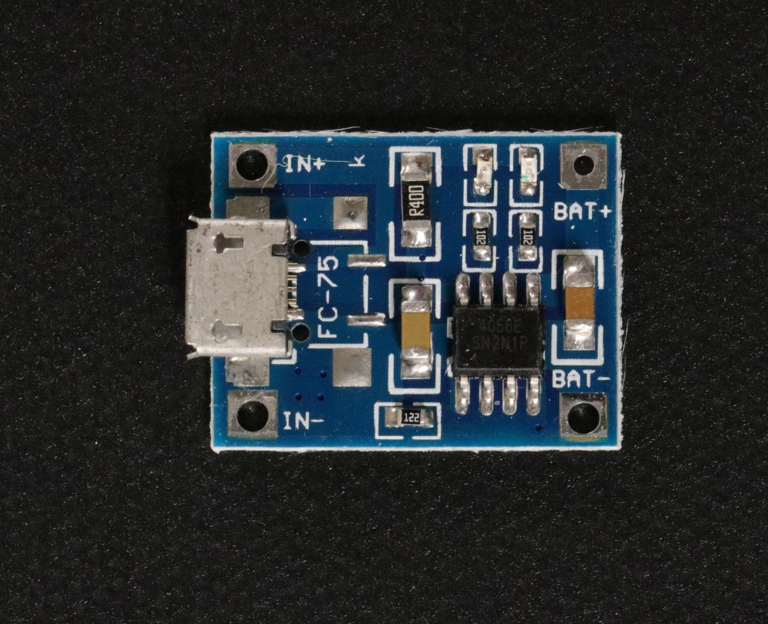

In [ ]:
from PIL import Image

type = "pcb"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_guidance_path = 'normal.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

**내 메모 (PCB + crack, 강사 출력)**
- **10-07 내 예측**: 작은 글자와 부품은 Stable Diffusion이 잘 유지할 것 같다 → 틀림. 글자가 `IN+` → `Joa d`로 바뀜.
- 처음엔 균열이 거의 안 보인다고 적었다. 10-10에 attention map과 나란히 보니 첫 장의 왼쪽 USB 커넥터가 찢어져 있었다. 균열을 실제로 생성한 것이었다.
- 나머지 3장은 attention 자리의 부품이 바뀌거나 얼룩이 생겼고 균열 모양은 아니었다.
- 이 사진에 불량 라벨을 붙이면? 글자는 선명한데 균열이 있는 진짜 불량이 오면 모델이 헷갈릴 것 같았는데, 모델은 둘 중 하나를 골라야 하니 글자를 보고 정상으로 판정할 것 같다 → 불량을 정상으로 넘기는 **미탐**. 생성 불량은 글자가 뭉개져 있어서 모델이 균열 대신 "글자가 뭉개졌나"를 배울 수 있다.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

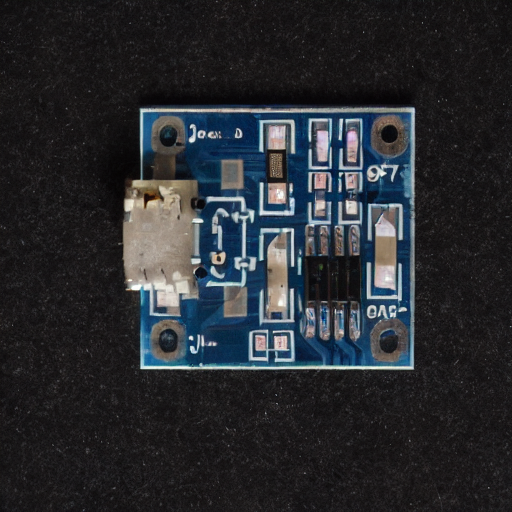

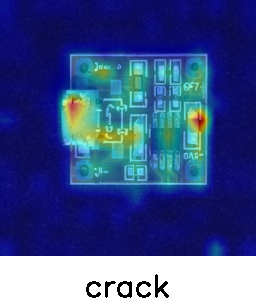

  0%|          | 0/200 [00:00<?, ?it/s]

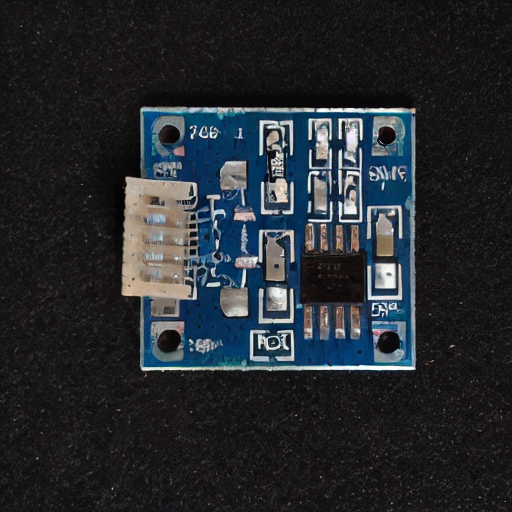

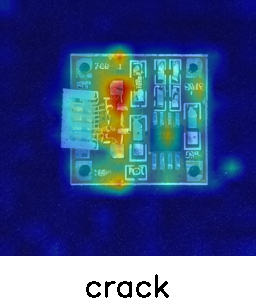

  0%|          | 0/200 [00:00<?, ?it/s]

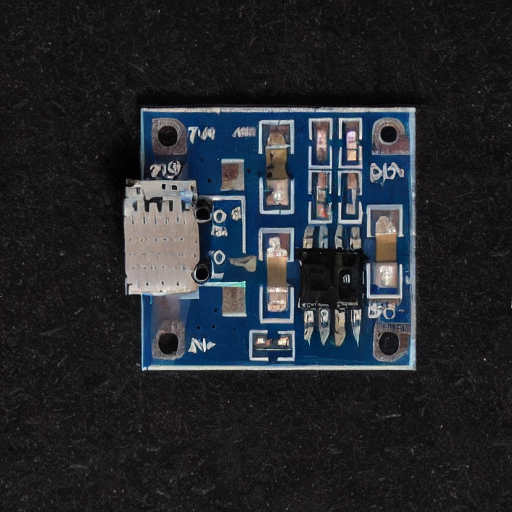

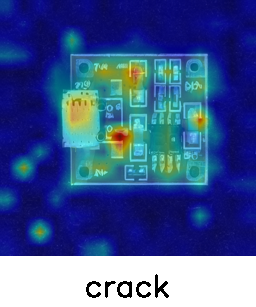

  0%|          | 0/200 [00:00<?, ?it/s]

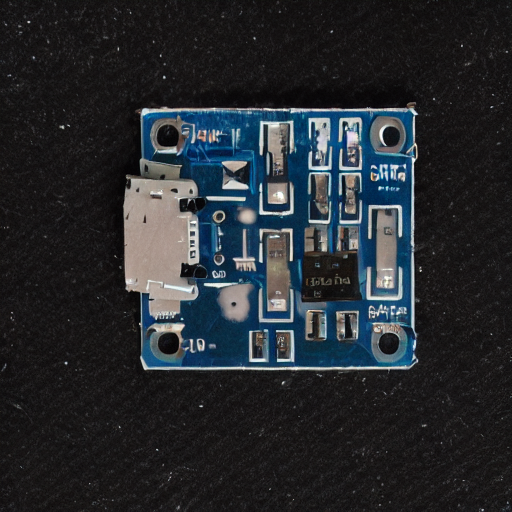

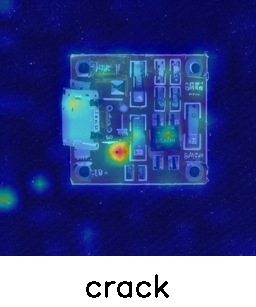

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

## 실험 C1. `init_image_guidance_scale` 0.3 vs 0.7 (T4에서 실행 불가)
- **내 예측**: 0.7이면 글자와 부품은 최대한 원본을 따르고, 균열은 잘 못 그려질 것 같다.
- 아래 셀 3개는 OOM을 피하려던 시도다. 해상도는 원인이 아니었다 (AnomalyAny 내부에서 생성 크기 512 고정). fp16은 dtype 에러, autocast는 요청이 1024 → 512MiB로 줄었지만 여전히 OOM.
- 두 번째 셀(512 재시도)의 원래 출력은 OOM이었는데, fp16 로드 뒤 이 셀을 다시 돌려서 지금은 dtype 에러가 남아 있다.
- 결론: L4(24GB) · A100 같은 더 큰 GPU가 필요하다. 비교는 못 했고 강사 출력을 분석하는 것으로 대신했다.

In [ ]:
# [실험 C1] init_image_guidance_scale 0.3 vs 0.7 (PCB + crack, 같은 시드 1234)
import shutil
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from run import get_indices_to_alter_new
from utils.ptp_utils import AttentionStore
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/normal.png의 사본', 'normal.png')
img = Image.open('normal.png').convert('RGB')
img.thumbnail((768, 768))
prompt = 'a photo of a pcb with a crack on it'
normal_prompt = 'a photo of a pcb'
detailed_prompt = 'a photo of a pcb with a large, jagged crack exposing the interior.'
idx = get_indices_to_alter_new(stable, prompt, '8')
outs = {}
for s in [0.3, 0.7]:
    g = torch.Generator('cuda').manual_seed(1234)
    image, _ = run_and_display(prompts=[prompt], controller=AttentionStore(), indices_to_alter=idx, init_image=img, init_image_guidance_scale=s, mask_image=None, generator=g, run_standard_sd=False, display_output=False, scale_factor=50, normal_prompt=normal_prompt, detailed_prompt=detailed_prompt)
    outs[s] = image
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [img.resize((512, 512)), outs[0.3], outs[0.7]], ['original', 'init_guidance 0.3', 'init_guidance 0.7']):
    a.imshow(im)
    a.set_title(t)
    a.axis('off')
plt.show()

Mounted at /content/drive
{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 413.81 MiB is free. Including non-PyTorch memory, this process has 14.16 GiB memory in use. Of the allocated memory 13.81 GiB is allocated by PyTorch, and 220.55 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
# [실험 C1 재시도] OOM → p.20대로 해상도 768 → 512 (SD1.5 기본 해상도). 나머지 동일
import gc
import shutil
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from run import get_indices_to_alter_new
from utils.ptp_utils import AttentionStore
gc.collect()
torch.cuda.empty_cache()
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/normal.png의 사본', 'normal.png')
img = Image.open('normal.png').convert('RGB').resize((512, 512))
prompt = 'a photo of a pcb with a crack on it'
normal_prompt = 'a photo of a pcb'
detailed_prompt = 'a photo of a pcb with a large, jagged crack exposing the interior.'
idx = get_indices_to_alter_new(stable, prompt, '8')
outs = {}
for s in [0.3, 0.7]:
    g = torch.Generator('cuda').manual_seed(1234)
    image, _ = run_and_display(prompts=[prompt], controller=AttentionStore(), indices_to_alter=idx, init_image=img, init_image_guidance_scale=s, mask_image=None, generator=g, run_standard_sd=False, display_output=False, scale_factor=50, normal_prompt=normal_prompt, detailed_prompt=detailed_prompt)
    outs[s] = image
    gc.collect()
    torch.cuda.empty_cache()
print('peak GPU memory (GB):', round(torch.cuda.max_memory_allocated() / 1e9, 2))
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [img, outs[0.3], outs[0.7]], ['original', 'init_guidance 0.3', 'init_guidance 0.7']):
    a.imshow(im)
    a.set_title(t)
    a.axis('off')
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

RuntimeError: mat1 and mat2 must have the same dtype, but got Float and Half

In [ ]:
# [실험 C1 autocast] fp32 모델 + 생성만 autocast(중간 계산 16비트)로 메모리 절감
import gc
import shutil
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from run import get_indices_to_alter_new
from utils.ptp_utils import AttentionStore
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/normal.png의 사본', 'normal.png')
img = Image.open('normal.png').convert('RGB').resize((512, 512))
prompt = 'a photo of a pcb with a crack on it'
normal_prompt = 'a photo of a pcb'
detailed_prompt = 'a photo of a pcb with a large, jagged crack exposing the interior.'
idx = get_indices_to_alter_new(stable, prompt, '8')
outs = {}
for s in [0.3, 0.7]:
    g = torch.Generator('cuda').manual_seed(1234)
    with torch.autocast('cuda'):
        image, _ = run_and_display(prompts=[prompt], controller=AttentionStore(), indices_to_alter=idx, init_image=img, init_image_guidance_scale=s, mask_image=None, generator=g, run_standard_sd=False, display_output=False, scale_factor=50, normal_prompt=normal_prompt, detailed_prompt=detailed_prompt)
    outs[s] = image
    gc.collect()
    torch.cuda.empty_cache()
print('peak GPU memory (GB):', round(torch.cuda.max_memory_allocated() / 1e9, 2))
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [img, outs[0.3], outs[0.7]], ['original', 'init_guidance 0.3', 'init_guidance 0.7']):
    a.imshow(im)
    a.set_title(t)
    a.axis('off')
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 512.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 131.81 MiB is free. Including non-PyTorch memory, this process has 14.43 GiB memory in use. Of the allocated memory 14.05 GiB is allocated by PyTorch, and 259.81 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

# 회고 (KPT)

**Keep**

- 돌리기 전에 결과를 먼저 말로 예상해 본 것. guidance가 크면 느려질 거라고 했는데 셋 다 4.5초였고, 여기서 guidance가 뭔지 제대로 알게 됐다.
- OOM이 났을 때 "해상도" 가설을 그냥 믿지 않고 AnomalyAny 소스를 열어 생성 크기가 512로 고정된 것을 확인한 것.
- 사흘 뒤 노트북을 처음부터 다시 보면서 attention map과 결과를 나란히 놓고, 처음 판단("균열 안 생김")을 고친 것.

**Problem**

- 처음엔 "본 적 없는 결함을 그린다"를 "원본을 바꿔서 그린다"로 이해했다. 모델은 그대로이고 생성 과정을 바꾼다는 걸 몰랐다.
- 오탐과 미탐의 이름을 두 번 바꿔 말했다. "경보를 울렸는데 틀림 = 오탐, 못 울림 = 미탐"으로 정리했다.
- C1의 실패한 시도 셀을 같은 노트북에서 다시 실행해서, 512 재시도의 OOM 출력이 덮어써졌다.
- AnomalyAny 결과를 처음엔 4장 중 1장만 보고 "커넥터에 균열을 그렸다"고 정리했다. 나머지 3장을 보고 나서 고쳤다. 시드가 랜덤이라 재현도 안 된다.

**Try / Action**

- [ ] L4 또는 A100 런타임에서 C1(원본 충실도 0.3 vs 0.7)을 같은 시드로 돌려 글자 보존과 균열 강도를 비교한다.
- [ ] B2의 마스크 경계를 가우시안 블러로 흐리게 섞어(feathering) 이음새가 사라지는지 확대 사진으로 확인한다.
- [ ] AnomalyAny 결과에 B2 되붙이기를 적용해, 커넥터 균열만 남기고 글자를 원본으로 돌린 사진을 만든다.
- [ ] 생성 불량 사진이 지름길을 만드는지 확인한다: 정상 실사진 vs 생성 불량으로 분류기를 학습한 뒤, 정상 사진의 글자만 살짝 흐리게 했을 때 불량으로 판정하는지 본다.